In [2]:
import pandas as pd
import numpy as np

In [3]:

# load the clean data and the measured-hours flags (both saved by the preprocessing notebook)
df = pd.read_csv(
    "henderson_model_no_future_interpolation.csv",
    index_col=0,
    parse_dates=True
)

df = df.sort_index()

print(df.shape)
print(df.head())

# True = really measured, False = a gap filled in during cleaning
measured = pd.read_csv("C:\\Users\\suraj\\Downloads\\henderson_measured_flags.csv", index_col="datetime", parse_dates=True).astype(bool)

print(df.shape, df.index.min(), "to", df.index.max())
print("share of hours really measured:")
print(measured.mean().round(3))

(150432, 5)
                      NO2  PM10    RH  Temp   WS
datetime                                        
2006-01-01 00:00:00  1.50  18.4  80.3  19.0  1.3
2006-01-01 01:00:00  0.76  32.6  81.1  19.0  3.1
2006-01-01 02:00:00  0.46  18.6  80.4  20.0  2.7
2006-01-01 03:00:00  0.42  15.1  79.4  20.0  1.6
2006-01-01 04:00:00  0.40  15.6  80.4  20.0  1.4
(150432, 5) 2006-01-01 00:00:00 to 2023-02-28 23:00:00
share of hours really measured:
NO2     0.878
PM10    0.956
RH      0.882
Temp    0.888
WS      0.895
dtype: float64


                                    Imports and leakage-safe feature preparation

In [5]:
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Ensure both sources are time-ordered and the flags are boolean.
df = df.sort_index()
measured = measured.sort_index().astype(bool)
assert df.index.is_unique, "Datetime index contains duplicate rows."

# IMPORTANT: cleaning/interpolation was done upstream on the full historical dataset.
# Audit that operation for time leakage; interpolation using future values is NOT
# appropriate for a strictly operational forecasting experiment.

def next_hour_features(data, pollutant):
    x = pd.DataFrame(index=data.index)
    x["hour"] = data.index.hour
    x["month"] = data.index.month
    x["dayofweek"] = data.index.dayofweek
    x["is_weekend"] = (data.index.dayofweek >= 5).astype(int)
    for weather in ["Temp", "RH", "WS"]:
        x[weather] = data[weather]
    for lag in [0, 1, 2, 3, 24]:
        x[f"{pollutant}_lag{lag}"] = data[pollutant].shift(lag)
    x[f"{pollutant}_roll3"] = data[pollutant].rolling(3, min_periods=3).mean()
    x[f"{pollutant}_roll24"] = data[pollutant].rolling(24, min_periods=24).mean()
    x["target"] = data[pollutant].shift(-1)
    x["measured_target"] = measured[pollutant].reindex(data.index + pd.Timedelta(hours=1), fill_value=False).to_numpy()
    return x.dropna(subset=["target", f"{pollutant}_lag0"])

def averaged_pm10_features(data, hours):
    x = pd.DataFrame(index=data.index)
    x["hour"] = data.index.hour
    x["month"] = data.index.month
    x["dayofweek"] = data.index.dayofweek
    x["is_weekend"] = (data.index.dayofweek >= 5).astype(int)
    x["fireworks_days"] = ((data.index.month == 11) & data.index.day.isin([4,5,6])).astype(int)
    x["era_2017"] = (data.index.year >= 2017).astype(int)
    for w in ["Temp", "RH", "WS"]:
        x[w] = data[w]
    for lag in [0,1,2,3,24]:
        x[f"PM10_lag{lag}"] = data["PM10"].shift(lag)
    x["PM10_roll3"] = data["PM10"].rolling(3, min_periods=2).mean()
    x["PM10_roll24"] = data["PM10"].rolling(24, min_periods=18).mean()
    x["PM10_std24"] = data["PM10"].rolling(24, min_periods=18).std()
    x["NO2_lag0"] = data["NO2"]
    x["NO2_roll24"] = data["NO2"].rolling(24, min_periods=18).mean()
    # Mean of t+1 through t+h. Require every future hour to be measured.
    # This stricter requirement avoids evaluating against interpolated targets.
    x["target"] = data["PM10"].rolling(hours, min_periods=hours).mean().shift(-hours)
    x["measured_target"] = measured["PM10"].astype(float).rolling(hours, min_periods=hours).min().shift(-hours).eq(1)
    return x.dropna(subset=["target", "PM10_lag0"])


In [7]:
# Fixed split by time, shared across all forecasting tasks.
# Original dataset is 2006-2023; these are 60/20/20 timestamps based on hourly index.
index = df.index.sort_values()
TRAIN_END = index[int(len(index) * 0.60)]
VALID_END = index[int(len(index) * 0.80)]
print("Train boundary:", TRAIN_END, "Validation/test boundary:", VALID_END)

def chronological_three_way(d, horizon):
    delta = pd.Timedelta(hours=horizon)
    train = d.loc[d.index + delta < TRAIN_END].copy()
    valid = d.loc[(d.index >= TRAIN_END) & (d.index + delta < VALID_END)].copy()
    test  = d.loc[d.index >= VALID_END].copy()
    assert len(train) and len(valid) and len(test), "One chronological partition is empty."
    print("Train", len(train), train.index.min(), train.index.max())
    print("Valid", len(valid), valid.index.min(), valid.index.max())
    print("Test ", len(test), test.index.min(), test.index.max())
    return train, valid, test

def score(y, p):
    return {"MAE": mean_absolute_error(y, p),
            "RMSE": float(np.sqrt(mean_squared_error(y, p))),
            "R2": r2_score(y, p)}


Train boundary: 2016-04-18 19:00:00 Validation/test boundary: 2019-09-24 09:00:00


In [9]:

# Define candidate models for validation-based selection

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

def candidate_models():
    return {
        "Linear Regression": [
            lambda: LinearRegression()
        ],

        "Decision Tree": [
            lambda: DecisionTreeRegressor(
                max_depth=5,
                random_state=42
            ),
            lambda: DecisionTreeRegressor(
                max_depth=10,
                random_state=42
            )
        ],

        "Random Forest": [
            lambda: RandomForestRegressor(
                n_estimators=100,
                max_depth=10,
                n_jobs=-1,
                random_state=42
            ),
            lambda: RandomForestRegressor(
                n_estimators=150,
                max_depth=15,
                n_jobs=-1,
                random_state=42
            )
        ],

        "XGBoost": [
            lambda: XGBRegressor(
                n_estimators=200,
                max_depth=3,
                learning_rate=0.05,
                random_state=42,
                n_jobs=-1
            ),
            lambda: XGBRegressor(
                n_estimators=300,
                max_depth=5,
                learning_rate=0.05,
                random_state=42,
                n_jobs=-1
            )
        ],

        "LightGBM": [
            lambda: LGBMRegressor(
                n_estimators=200,
                learning_rate=0.05,
                num_leaves=31,
                verbose=-1,
                random_state=42
            ),
            lambda: LGBMRegressor(
                n_estimators=300,
                learning_rate=0.05,
                num_leaves=15,
                objective="huber",
                verbose=-1,
                random_state=42
            )
        ]
    }

print("Candidate models loaded successfully.")


Candidate models loaded successfully.


In [10]:

def compare_on_validation(train, valid, cols, naive_col):
    """
    Compare candidate models using chronological validation data.

    Models are trained on train.
    Model selection uses valid only.
    The test set is not used in this function.
    """

    rows = []

    # 1. Identify genuinely measured validation targets.
    measured_valid = (
        valid["measured_target"]
        .fillna(False)
        .astype(bool)
    )

    # 2. Use the same observations for models and baseline.
    # Exclude missing targets, missing baseline predictions,
    # and missing predictor values.
    valid_mask = (
        measured_valid
        & valid["target"].notna()
        & valid[naive_col].notna()
        & np.isfinite(valid["target"])
        & np.isfinite(valid[naive_col])
        & valid[cols].notna().all(axis=1)
    )

    if valid_mask.sum() < 2:
        raise ValueError(
            "Not enough valid measured observations "
            "for validation."
        )

    X_valid = valid.loc[valid_mask, cols]
    y_valid = valid.loc[valid_mask, "target"]

    # 3. Prepare training data.
    train_mask = (
        train["target"].notna()
        & np.isfinite(train["target"])
        & train[cols].notna().all(axis=1)
    )

    X_train = train.loc[train_mask, cols]
    y_train = train.loc[train_mask, "target"]

    if len(X_train) == 0:
        raise ValueError("No valid training observations.")

    # 4. Evaluate the persistence baseline.
    naive_pred = valid.loc[valid_mask, naive_col]

    naive_metrics = score(y_valid, naive_pred)

    print("\nPersistence baseline:")
    print(naive_metrics)
    print("Validation observations:", len(y_valid))

    # 5. Train and validate candidate models.
    factories_by_name = candidate_models()

    for name, factories in factories_by_name.items():

        for candidate, factory in enumerate(factories, 1):

            model = factory()

            model.fit(X_train, y_train)

            predictions = model.predict(X_valid)

            metrics = score(y_valid, predictions)

            rows.append({
                "model": name,
                "candidate": candidate,
                **metrics
            })

    # 6. Rank models by validation RMSE.
    results = (
        pd.DataFrame(rows)
        .sort_values("RMSE", ascending=True)
        .reset_index(drop=True)
    )

    print("\nValidation model comparison:")
    display(results)

    # 7. Select best model using validation only.
    winner = results.iloc[0]

    winner_name = winner["model"]
    winner_idx = int(winner["candidate"])

    factory = factories_by_name[winner_name][winner_idx - 1]

    print("\nBest model:", winner_name)
    print("Candidate:", winner_idx)
    print("Validation RMSE:", round(winner["RMSE"], 3))
    print("Validation R2:", round(winner["R2"], 3))

    # 8. Return results for final evaluation.
    return results, winner_name, winner_idx, factory


In [12]:

def final_evaluation(train, valid, test, cols, factory, naive_col, task):
    """
    Fit the selected model on training + validation data.
    Evaluate on the final chronological test period.
    Use the same observations for the model and baseline.
    """

    # 1. Combine training and validation data
    development = pd.concat([train, valid]).sort_index()

    # 2. Prepare valid training observations
    train_mask = (
        development["target"].notna()
        & np.isfinite(development["target"])
        & development[cols].notna().all(axis=1)
    )

    X_train = development.loc[train_mask, cols]
    y_train = development.loc[train_mask, "target"]

    if len(X_train) == 0:
        raise ValueError("No valid training observations.")

    # 3. Select genuinely measured test observations
    measured_test = (
        test["measured_target"]
        .fillna(False)
        .astype(bool)
    )

    # 4. Use identical test observations for model and baseline
    test_mask = (
        measured_test
        & test["target"].notna()
        & test[naive_col].notna()
        & np.isfinite(test["target"])
        & np.isfinite(test[naive_col])
        & test[cols].notna().all(axis=1)
    )

    if test_mask.sum() < 2:
        raise ValueError("Not enough valid test observations.")

    X_test = test.loc[test_mask, cols]
    y_test = test.loc[test_mask, "target"]

    # 5. Train the selected model
    model = factory()
    model.fit(X_train, y_train)

    # 6. Predict on the test set
    predictions = model.predict(X_test)

    # 7. Evaluate the model
    metrics = score(y_test, predictions)

    # 8. Evaluate the persistence baseline
    baseline_predictions = test.loc[test_mask, naive_col]
    baseline = score(y_test, baseline_predictions)

    # 9. Display results
    print("\n" + "=" * 50)
    print("FINAL EVALUATION:", task)
    print("=" * 50)

    print("Test observations:", len(y_test))

    print("\nSelected model:")
    print("MAE :", round(metrics["MAE"], 3))
    print("RMSE:", round(metrics["RMSE"], 3))
    print("R²  :", round(metrics["R2"], 3))

    print("\nPersistence baseline:")
    print("MAE :", round(baseline["MAE"], 3))
    print("RMSE:", round(baseline["RMSE"], 3))
    print("R²  :", round(baseline["R2"], 3))

    # 10. Return predictions with matching timestamps
    pred = pd.Series(
        predictions,
        index=X_test.index,
        name="predicted"
    )

    return model, pred, metrics, baseline


In [13]:
tasks = {
    "NO2_next_hour": (next_hour_features(df, "NO2"), 1, "NO2_lag0"),
    "PM10_next_hour": (next_hour_features(df, "PM10"), 1, "PM10_lag0"),
    "PM10_next_3h_average": (averaged_pm10_features(df, 3), 3, "PM10_roll3"),
    "PM10_next_24h_average": (averaged_pm10_features(df, 24), 24, "PM10_roll24"),
}
validation_tables = {}
models_final = {}
final_summary = []
prediction_outputs = {}
for task, (all_data, horizon, naive_col) in tasks.items():
    print("\n============",task,"============")
    train, valid, test = chronological_three_way(all_data, horizon)
    columns = [c for c in all_data.columns if c not in ["target", "measured_target", "era_2017"]]
    # Optional regime flag can be compared on validation only; do not choose using test.
    validation, winner_name, winner_idx, factory = compare_on_validation(train, valid, columns, naive_col)
    validation_tables[task] = validation
    model, pred, metrics, baseline = final_evaluation(train, valid, test, columns, factory, naive_col, task)
    models_final[task] = {"model": model, "features": columns, "selection":winner_name, "candidate":winner_idx}
    prediction_outputs[task] = pd.DataFrame({"datetime":pred.index, "actual":test.loc[pred.index,"target"].values,"predicted":pred.values})
    final_summary.append({"Task":task, "Selected on validation":winner_name, **metrics, "Baseline_R2":baseline["R2"]})
final_summary = pd.DataFrame(final_summary)
display(final_summary)



============ NO2_next_hour ============
Train 88936 2006-01-01 00:00:00 2016-04-18 17:00:00
Valid 18412 2016-04-18 19:00:00 2019-09-24 07:00:00
Test  28437 2019-09-24 09:00:00 2023-02-28 22:00:00

Persistence baseline:
{'MAE': 3.783223888410044, 'RMSE': 6.197075986820236, 'R2': 0.6459741414301304}
Validation observations: 17403

Validation model comparison:


,model,candidate,MAE,RMSE,R2
0,LightGBM,1,3.071262,4.761832,0.790970
1,XGBoost,2,3.098798,4.804686,0.787190
2,Random Forest,2,3.149170,4.944373,0.774636
3,Random Forest,1,3.235043,5.080199,0.762084
4,XGBoost,1,3.325991,5.108673,0.759410
5,Decision Tree,2,3.407114,5.392763,0.731908
6,Linear Regression,1,3.762935,5.704938,0.699971
7,Decision Tree,1,3.761336,5.710888,0.699345
8,LightGBM,2,3.695167,6.103757,0.656556



Best model: LightGBM
Candidate: 1
Validation RMSE: 4.762
Validation R2: 0.791

FINAL EVALUATION: NO2_next_hour
Test observations: 16495

Selected model:
MAE : 2.307
RMSE: 3.566
R²  : 0.762

Persistence baseline:
MAE : 2.601
RMSE: 4.459
R²  : 0.628

============ PM10_next_hour ============
Train 89165 2006-01-01 00:00:00 2016-04-18 17:00:00
Valid 28752 2016-04-18 19:00:00 2019-09-24 07:00:00
Test  28300 2019-09-24 09:00:00 2023-02-28 22:00:00

Persistence baseline:
{'MAE': 5.09226031687546, 'RMSE': 6.922093904998901, 'R2': 0.17257859849994261}
Validation observations: 25783

Validation model comparison:


,model,candidate,MAE,RMSE,R2
0,LightGBM,1,4.033292,5.454351,0.486266
1,XGBoost,2,4.033583,5.524626,0.472943
2,XGBoost,1,4.135875,5.593329,0.459753
3,Random Forest,2,4.113264,5.643979,0.449924
4,Random Forest,1,4.147528,5.684721,0.441954
5,LightGBM,2,4.304357,5.903965,0.398079
6,Linear Regression,1,4.382561,5.944481,0.389789
7,Decision Tree,2,4.299029,6.110939,0.355137
8,Decision Tree,1,4.442648,6.216043,0.332764



Best model: LightGBM
Candidate: 1
Validation RMSE: 5.454
Validation R2: 0.486

FINAL EVALUATION: PM10_next_hour
Test observations: 16432

Selected model:
MAE : 4.179
RMSE: 5.775
R²  : 0.333

Persistence baseline:
MAE : 5.339
RMSE: 7.151
R²  : -0.023

============ PM10_next_3h_average ============
Train 89109 2006-01-01 00:00:00 2016-04-18 15:00:00
Valid 28732 2016-04-18 19:00:00 2019-09-24 05:00:00
Test  28280 2019-09-24 09:00:00 2023-02-28 20:00:00

Persistence baseline:
{'MAE': 4.056327071615184, 'RMSE': 5.784348201140952, 'R2': 0.21278720552496788}
Validation observations: 17352

Validation model comparison:


,model,candidate,MAE,RMSE,R2
0,LightGBM,1,3.144990,4.375256,0.549608
1,XGBoost,2,3.155504,4.389962,0.546576
2,XGBoost,1,3.283865,4.539583,0.515141
3,Random Forest,2,3.233194,4.715131,0.476917
4,LightGBM,2,3.402449,4.768712,0.464961
5,Random Forest,1,3.299678,4.806398,0.456471
6,Linear Regression,1,3.504746,4.835475,0.449875
7,Decision Tree,2,3.485189,5.392531,0.315823
8,Decision Tree,1,3.710744,5.500935,0.288039



Best model: LightGBM
Candidate: 1
Validation RMSE: 4.375
Validation R2: 0.55

FINAL EVALUATION: PM10_next_3h_average
Test observations: 15520

Selected model:
MAE : 3.054
RMSE: 4.291
R²  : 0.441

Persistence baseline:
MAE : 3.646
RMSE: 5.169
R²  : 0.188

============ PM10_next_24h_average ============
Train 88544 2006-01-01 00:00:00 2016-04-17 18:00:00
Valid 28522 2016-04-18 19:00:00 2019-09-23 08:00:00
Test  28070 2019-09-24 09:00:00 2023-02-27 23:00:00

Persistence baseline:
{'MAE': 3.290995149108138, 'RMSE': 4.349071627305132, 'R2': -0.0011107273434936005}
Validation observations: 15249

Validation model comparison:


,model,candidate,MAE,RMSE,R2
0,LightGBM,2,2.654183,3.468887,0.363103
1,XGBoost,1,2.718888,3.498363,0.352233
2,LightGBM,1,2.715910,3.514121,0.346384
3,XGBoost,2,2.718928,3.518438,0.344778
4,Linear Regression,1,2.809300,3.622677,0.305379
5,Random Forest,1,2.762130,3.689353,0.279574
6,Random Forest,2,2.787384,3.747733,0.256593
7,Decision Tree,1,2.852221,3.931630,0.181847
8,Decision Tree,2,2.950099,4.188566,0.071419



Best model: LightGBM
Candidate: 2
Validation RMSE: 3.469
Validation R2: 0.363

FINAL EVALUATION: PM10_next_24h_average
Test observations: 10167

Selected model:
MAE : 2.507
RMSE: 3.356
R²  : 0.387

Persistence baseline:
MAE : 2.9
RMSE: 3.9
R²  : 0.172


,Task,Selected on validation,MAE,RMSE,R2,Baseline_R2
0,NO2_next_hour,LightGBM,2.307140,3.566494,0.761870,0.627745
1,PM10_next_hour,LightGBM,4.178960,5.774977,0.332703,-0.023298
2,PM10_next_3h_average,LightGBM,3.053510,4.290585,0.440644,0.188021
3,PM10_next_24h_average,LightGBM,2.507151,3.356489,0.387174,0.172452


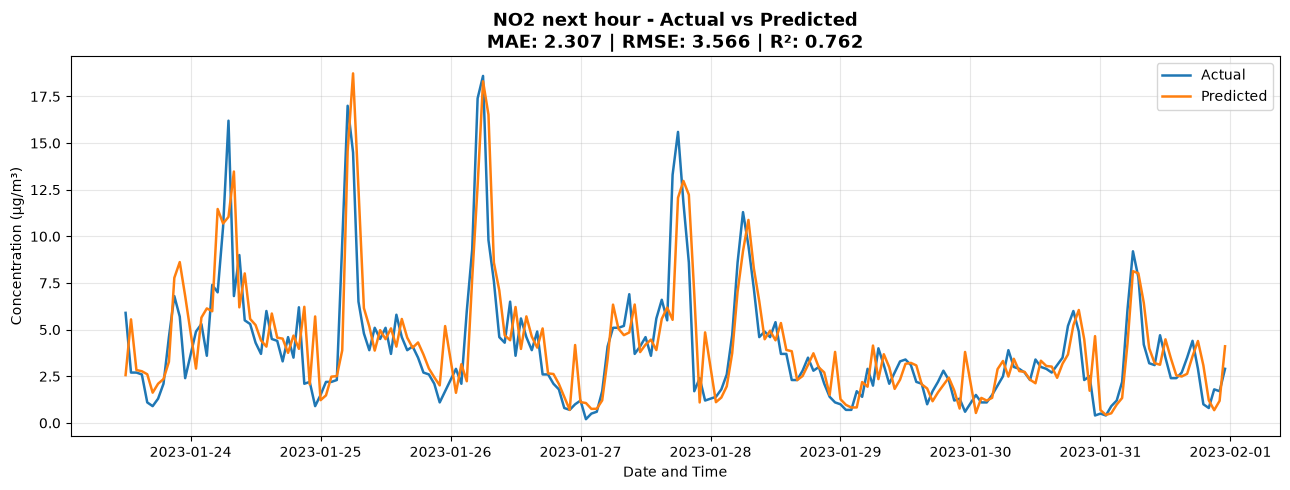


Task: NO2_next_hour
Test observations: 16495
MAE: 2.307
RMSE: 3.566
R²: 0.762


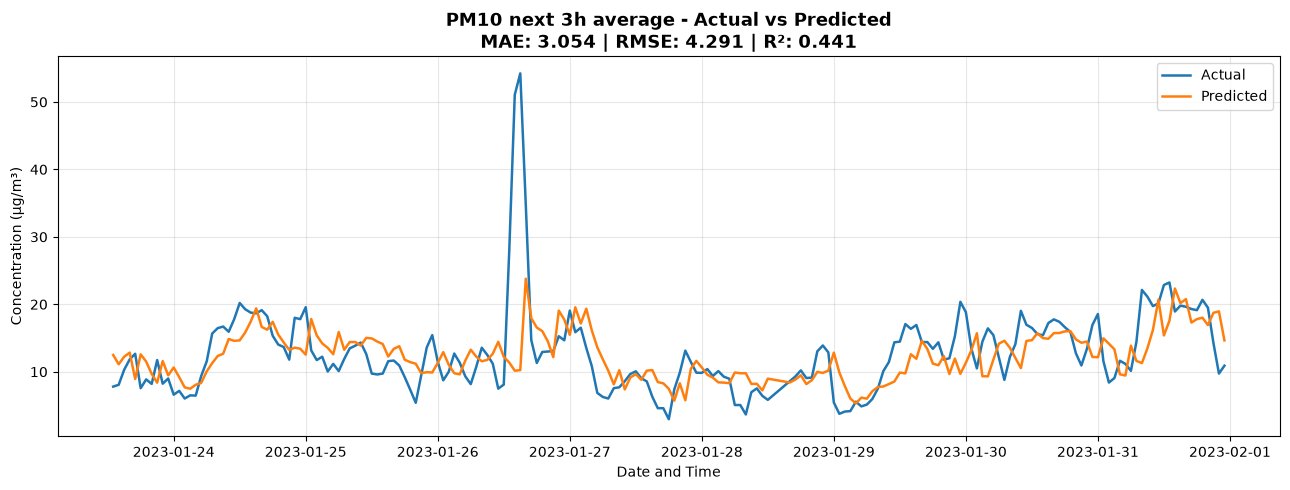


Task: PM10_next_3h_average
Test observations: 15520
MAE: 3.054
RMSE: 4.291
R²: 0.441


In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def plot_actual_vs_predicted(task, last_n=200):

    # 1. Retrieve final test predictions
    df = prediction_outputs[task].copy()

    # 2. Prepare datetime and values
    df["datetime"] = pd.to_datetime(df["datetime"])

    df["actual"] = pd.to_numeric(
        df["actual"], errors="coerce"
    )

    df["predicted"] = pd.to_numeric(
        df["predicted"], errors="coerce"
    )

    # 3. Remove invalid rows
    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.dropna(
        subset=["datetime", "actual", "predicted"]
    )

    # 4. Calculate metrics on the FULL test set
    mae = mean_absolute_error(
        df["actual"], df["predicted"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            df["actual"], df["predicted"]
        )
    )

    r2 = r2_score(
        df["actual"], df["predicted"]
    )

    # 5. Select observations for plotting only
    df_plot = (
        df.sort_values("datetime")
          .tail(last_n)
    )

    # 6. Create Actual vs Predicted graph
    plt.figure(figsize=(13, 5))

    plt.plot(
        df_plot["datetime"],
        df_plot["actual"],
        label="Actual",
        linewidth=1.8
    )

    plt.plot(
        df_plot["datetime"],
        df_plot["predicted"],
        label="Predicted",
        linewidth=1.8
    )

    # 7. Add updated metrics to the title
    plt.title(
        f"{task.replace('_', ' ')} - Actual vs Predicted\n"
        f"MAE: {mae:.3f} | "
        f"RMSE: {rmse:.3f} | "
        f"R²: {r2:.3f}",
        fontsize=13,
        fontweight="bold"
    )

    plt.xlabel("Date and Time")
    plt.ylabel("Concentration (µg/m³)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"\nTask: {task}")
    print(f"Test observations: {len(df)}")
    print(f"MAE: {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")
    print(f"R²: {r2:.3f}")


# Graph 1: NO2 next-hour prediction
plot_actual_vs_predicted("NO2_next_hour")

# Graph 2: PM10 next 3-hour average prediction
plot_actual_vs_predicted("PM10_next_3h_average")


In [16]:
%pip install prophet

Note: you may need to restart the kernel to use updated packages.


In [17]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate performance metrics
def prophet_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }


# Convert modelling data to Prophet format
def prepare_prophet_data(data):
    df = data.copy()

    # Datetime index -> Prophet's ds column
    df["ds"] = pd.to_datetime(df.index)
    df["y"] = pd.to_numeric(df["target"], errors="coerce")

    df = df.dropna(subset=["ds", "y"])
    df = df.sort_values("ds")

    return df[["ds", "y"]]


# Evaluate one forecasting task
def evaluate_prophet(task, all_data, horizon, naive_col):

    print("\n" + "=" * 55)
    print("PROPHET:", task)
    print("=" * 55)

    # Use your existing chronological split function
    train, valid, test = chronological_three_way(
        all_data, horizon
    )

    train_p = prepare_prophet_data(train)
    valid_p = prepare_prophet_data(valid)
    test_p = prepare_prophet_data(test)

    # Select genuinely measured validation observations
    valid_mask = valid["measured_target"].fillna(False).astype(bool)
    valid_mask &= valid["target"].notna()
    valid_mask &= valid[naive_col].notna()

    # Two Prophet parameter candidates
    candidates = [
        {
            "changepoint_prior_scale": 0.05,
            "seasonality_prior_scale": 10.0
        },
        {
            "changepoint_prior_scale": 0.1,
            "seasonality_prior_scale": 5.0
        }
    ]

    validation_results = []

    # -------- VALIDATION --------
    for i, params in enumerate(candidates, 1):

        model = Prophet(
            daily_seasonality=True,
            weekly_seasonality=True,
            yearly_seasonality=True,
            **params
        )

        model.fit(train_p)

        future_valid = pd.DataFrame({
            "ds": pd.to_datetime(valid.loc[valid_mask].index)
        })

        predictions = model.predict(future_valid)["yhat"].values
        actual = valid.loc[valid_mask, "target"].values

        metrics = prophet_metrics(actual, predictions)

        validation_results.append({
            "Candidate": i,
            **params,
            **metrics
        })

    validation_table = pd.DataFrame(validation_results)
    validation_table = validation_table.sort_values("RMSE")

    print("\nProphet validation results:")
    display(validation_table)

    # Select best candidate using validation only
    best = validation_table.iloc[0]

    best_params = {
        "changepoint_prior_scale": best["changepoint_prior_scale"],
        "seasonality_prior_scale": best["seasonality_prior_scale"]
    }

    print("\nSelected Prophet parameters:", best_params)

    # -------- FINAL EVALUATION --------

    # Combine training and validation periods
    development = pd.concat([train, valid]).sort_index()
    development_p = prepare_prophet_data(development)

    final_model = Prophet(
        daily_seasonality=True,
        weekly_seasonality=True,
        yearly_seasonality=True,
        **best_params
    )

    final_model.fit(development_p)

    # Evaluate on genuinely measured test targets
    test_mask = test["measured_target"].fillna(False).astype(bool)
    test_mask &= test["target"].notna()
    test_mask &= test[naive_col].notna()

    future_test = pd.DataFrame({
        "ds": pd.to_datetime(test.loc[test_mask].index)
    })

    forecast = final_model.predict(future_test)

    actual = test.loc[test_mask, "target"].values
    predicted = forecast["yhat"].values

    metrics = prophet_metrics(actual, predicted)

    baseline = prophet_metrics(
        actual,
        test.loc[test_mask, naive_col].values
    )

    print("\nFINAL PROPHET TEST RESULTS")
    print("Test observations:", len(actual))
    print("MAE :", round(metrics["MAE"], 3))
    print("RMSE:", round(metrics["RMSE"], 3))
    print("R²  :", round(metrics["R2"], 3))

    print("\nPersistence baseline:")
    print("R²:", round(baseline["R2"], 3))

    # Save results for comparison and plotting
    outputs = pd.DataFrame({
        "datetime": future_test["ds"].values,
        "actual": actual,
        "predicted": predicted
    })

    return final_model, validation_table, metrics, outputs


In [18]:

# Run Prophet using the same datasets and time splits

prophet_results = {}
prophet_predictions = {}

for task, (all_data, horizon, naive_col) in tasks.items():

    print("\nRunning Prophet:", task)

    model, validation, metrics, outputs = evaluate_prophet(
        task,
        all_data,
        horizon,
        naive_col
    )

    prophet_results[task] = {
        "model": model,
        "validation": validation,
        "metrics": metrics
    }

    prophet_predictions[task] = outputs

print("All Prophet evaluations completed.")



Running Prophet: NO2_next_hour

PROPHET: NO2_next_hour
Train 88936 2006-01-01 00:00:00 2016-04-18 17:00:00
Valid 18412 2016-04-18 19:00:00 2019-09-24 07:00:00
Test  28437 2019-09-24 09:00:00 2023-02-28 22:00:00


19:31:55 - cmdstanpy - INFO - Chain [1] start processing
19:32:31 - cmdstanpy - INFO - Chain [1] done processing
19:32:54 - cmdstanpy - INFO - Chain [1] start processing
19:33:45 - cmdstanpy - INFO - Chain [1] done processing



Prophet validation results:


,Candidate,changepoint_prior_scale,seasonality_prior_scale,MAE,RMSE,R2
1,2,0.10,5.0,7.230752,9.208774,0.215393
0,1,0.05,10.0,7.224164,9.208906,0.215370



Selected Prophet parameters: {'changepoint_prior_scale': np.float64(0.1), 'seasonality_prior_scale': np.float64(5.0)}


...


Prophet validation results:


,Candidate,changepoint_prior_scale,seasonality_prior_scale,MAE,RMSE,R2
1,2,0.10,5.0,3.720399,4.933657,-0.299107
0,1,0.05,10.0,3.721305,4.933840,-0.299204



Selected Prophet parameters: {'changepoint_prior_scale': np.float64(0.1), 'seasonality_prior_scale': np.float64(5.0)}


19:45:13 - cmdstanpy - INFO - Chain [1] start processing
19:46:17 - cmdstanpy - INFO - Chain [1] done processing



FINAL PROPHET TEST RESULTS
Test observations: 14693
MAE : 3.255
RMSE: 4.404
R²  : -0.14

Persistence baseline:
R²: 0.131
All Prophet evaluations completed.


In [35]:
os.makedirs("models_validation_fixed", exist_ok=True)
for task, bundle in models_final.items():
    joblib.dump(bundle, f"models_validation_fixed/{task}.joblib", compress=3)
    validation_tables[task].to_csv(f"models_validation_fixed/{task}_validation_comparison.csv", index=False)
    prediction_outputs[task].to_csv(f"models_validation_fixed/{task}_retrospective_test_predictions.csv", index=False)
final_summary.to_csv("models_validation_fixed/revised_retrospective_metrics.csv", index=False)
print("Saved revised models and evaluation evidence; existing Streamlit models remain unchanged.")


Saved revised models and evaluation evidence; existing Streamlit models remain unchanged.


In [37]:
models_final

{'NO2_next_hour': {'model': LGBMRegressor(learning_rate=0.05, n_estimators=200, random_state=42, verbose=-1),
  'features': ['hour',
   'month',
   'dayofweek',
   'is_weekend',
   'Temp',
   'RH',
   'WS',
   'NO2_lag0',
   'NO2_lag1',
   'NO2_lag2',
   'NO2_lag3',
   'NO2_lag24',
   'NO2_roll3',
   'NO2_roll24'],
  'selection': 'LightGBM',
  'candidate': 1},
 'PM10_next_hour': {'model': LGBMRegressor(learning_rate=0.05, n_estimators=200, random_state=42, verbose=-1),
  'features': ['hour',
   'month',
   'dayofweek',
   'is_weekend',
   'Temp',
   'RH',
   'WS',
   'PM10_lag0',
   'PM10_lag1',
   'PM10_lag2',
   'PM10_lag3',
   'PM10_lag24',
   'PM10_roll3',
   'PM10_roll24'],
  'selection': 'LightGBM',
  'candidate': 1},
 'PM10_next_3h_average': {'model': LGBMRegressor(learning_rate=0.05, n_estimators=200, random_state=42, verbose=-1),
  'features': ['hour',
   'month',
   'dayofweek',
   'is_weekend',
   'fireworks_days',
   'Temp',
   'RH',
   'WS',
   'PM10_lag0',
   'PM10_lag1',

In [39]:
print(models_final.keys())

dict_keys(['NO2_next_hour', 'PM10_next_hour', 'PM10_next_3h_average', 'PM10_next_24h_average'])


In [41]:
import joblib
from pathlib import Path

# Save updated models in a separate folder first
output_dir = Path("models_revised")
output_dir.mkdir(exist_ok=True)

file_names = {
    "NO2_next_hour": "best_model_NO2.pkl",
    "PM10_next_hour": "best_model_PM10.pkl",
    "PM10_next_3h_average": "pm10_3h_model.pkl",
    "PM10_next_24h_average": "pm10_24h_model.pkl"
}

for task, filename in file_names.items():
    saved = models_final[task]

    # Save the model together with its exact training features
    joblib.dump(
        {
            "model": saved["model"],
            "features": saved["features"],
            "name": saved["selection"]
        },
        output_dir / filename
    )

    print("Saved:", output_dir / filename)

Saved: models_revised\best_model_NO2.pkl
Saved: models_revised\best_model_PM10.pkl
Saved: models_revised\pm10_3h_model.pkl
Saved: models_revised\pm10_24h_model.pkl
